# CART (Classification and Regression Trees) Using Python
## Bank Marketing Term Deposit Subscription Prediction

### 1. Aim
To implement the **CART classification algorithm** using the Bank Marketing dataset and predict whether a customer will subscribe to a term deposit.

### 2. Objectives
- Explore and understand the Bank Marketing dataset.
- Identify the input features and target variable.
- Check missing values, duplicate records, and class distribution.
- Understand Gini impurity and weighted Gini impurity.
- Build a CART classification model using a binary decision tree.
- Visualize the decision tree and feature importance.
- Evaluate predictions using a confusion matrix, accuracy, precision, recall, F1-score, and ROC-AUC.

### 3. Dataset Description
- **Dataset:** `bank-full.csv` (Bank Marketing dataset)
- **Rows:** 45,211
- **Columns:** 17
- **Target variable:** `y`
  - `yes` – the customer subscribed to a term deposit.
  - `no` – the customer did not subscribe.

The file is semicolon-separated (`;`), so it must be loaded using `sep=';'`.

### 4. Algorithm
CART stands for **Classification and Regression Trees**. It is a supervised learning algorithm used for classification and regression. A CART tree creates binary splits. For classification, the Gini impurity criterion can be used to choose splits that make the resulting child nodes as pure as possible.

\[
Gini = 1 - \sum_{i=1}^{k} p_i^2
\]

For a binary target:

\[
Gini = 1 - (p_{no}^2 + p_{yes}^2)
\]

The weighted Gini impurity after a split is:

\[
Gini_{split} = \frac{N_L}{N}Gini_L + \frac{N_R}{N}Gini_R
\]

The split with the lowest weighted Gini impurity (equivalently, the greatest Gini reduction) is preferred.

### 5. Important modelling decision
The column `duration` records the length of the current/last contact. It is only known after the call has taken place. To model whether a customer may subscribe **before contacting them**, this notebook excludes `duration` to avoid target leakage. The target `y` is also excluded from the input features.

### 6. Expected Outcome
A trained CART classifier that predicts term-deposit subscription and reports its performance on unseen test records.

## Step 1: Import required libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load the Bank Marketing dataset
The CSV file is separated by semicolons. Keep `bank-full.csv` in the same folder as this notebook.

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## Step 3: Display the first five records

In [3]:
display(df.head())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Step 4: Check the number of rows and columns

In [4]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (45211, 17)
Number of rows: 45211
Number of columns: 17


## Step 5: Understand the dataset structure

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


## Step 6: Statistical summary

In [6]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


## Step 7: Check missing values
Missing values can affect model training. This dataset may use text values such as `unknown` as a category; those are not the same as pandas null values.

In [7]:
missing_values = df.isnull().sum().sort_values(ascending=False)
display(missing_values.to_frame("Missing Values"))
print("Total missing cells:", int(df.isnull().sum().sum()))

,Missing Values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Total missing cells: 0


## Step 8: Check duplicate records

In [8]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


## Step 9: Analyze the target variable
The target `y` indicates whether the customer subscribed to a term deposit. The target classes are imbalanced, so accuracy alone will not be sufficient to judge the model.

In [9]:
print("Target class counts:")
display(df["y"].value_counts().to_frame("Count"))

print("\nTarget class percentages:")
display((df["y"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

Target class counts:


,Count
y,
no,39922
yes,5289



Target class percentages:


,Percentage
y,
no,88.3
yes,11.7


## Step 10: Visualize target distribution

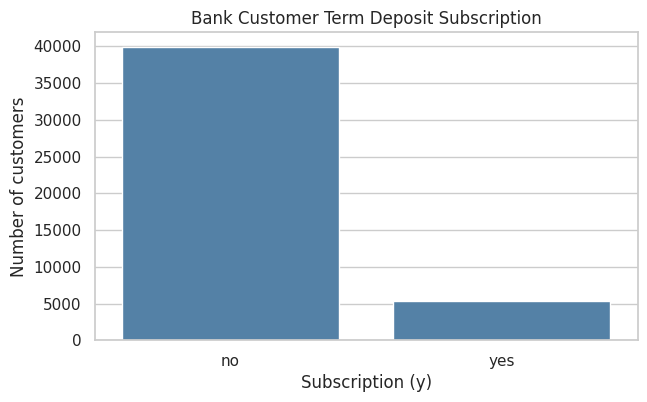

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="y", order=["no", "yes"], color="steelblue")
plt.title("Bank Customer Term Deposit Subscription")
plt.xlabel("Subscription (y)")
plt.ylabel("Number of customers")
plt.show()

## Step 11: Select input features and target variable
`y` is the target. `duration` is excluded because it is only known after the contact and could leak information into a pre-contact prediction model.

In [11]:
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

print("Input feature columns:")
print(X.columns.tolist())
print("\nTarget mapping: no = 0, yes = 1")
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input feature columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target mapping: no = 0, yes = 1
Input shape: (45211, 15)
Target shape: (45211,)


## Step 12: Identify numerical and categorical features
Numerical columns are passed through a median imputer. Categorical columns are imputed with their most frequent value and converted to numeric indicator columns using one-hot encoding.

In [12]:
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Number of numerical features: 6
Number of categorical features: 9


## Step 13: Split the dataset into training and testing sets
We use an 80:20 split. `stratify=y` preserves approximately the same target-class proportions in both sets. Preprocessing is fitted only on the training data through a pipeline, preventing preprocessing leakage.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())
print("Testing target distribution:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Training feature shape: (36168, 15)
Testing feature shape: (9043, 15)
Training target shape: (36168,)
Testing target shape: (9043,)

Training target distribution:


,Proportion
y,
0,0.883018
1,0.116982


Testing target distribution:


,Proportion
y,
0,0.883003
1,0.116997


## Step 14: Calculate parent Gini impurity
The parent Gini impurity is calculated from the target distribution in the training set, before making a split.

In [14]:
def calculate_gini(target):
    """Calculate Gini impurity for a target Series."""
    probabilities = target.value_counts(normalize=True)
    return 1 - np.sum(probabilities ** 2)

parent_gini = calculate_gini(y_train)
print("Training records:", len(y_train))
print("Class 0 proportion (no):", round((y_train == 0).mean(), 4))
print("Class 1 proportion (yes):", round((y_train == 1).mean(), 4))
print("Parent Gini impurity:", round(parent_gini, 6))

Training records: 36168
Class 0 proportion (no): 0.883
Class 1 proportion (yes): 0.117
Parent Gini impurity: 0.206594


## Step 15: Calculate weighted Gini for a categorical feature
For a simple binary CART split, one category is compared against all remaining categories. The weighted Gini is the size-weighted impurity of the two child groups.

In [15]:
def weighted_gini_for_split(target, left_mask):
    left = target[left_mask]
    right = target[~left_mask]

    if len(left) == 0 or len(right) == 0:
        return np.nan

    return (
        (len(left) / len(target)) * calculate_gini(left)
        + (len(right) / len(target)) * calculate_gini(right)
    )

feature_name = "marital"
feature_values = X_train[feature_name]
categorical_split_results = []

for category in sorted(feature_values.unique()):
    mask = feature_values == category
    split_gini = weighted_gini_for_split(y_train, mask)
    categorical_split_results.append({
        "Feature": feature_name,
        "Split": f"{category} vs remaining",
        "Weighted Gini": split_gini,
        "Gini Reduction": parent_gini - split_gini
    })

categorical_gini_df = pd.DataFrame(categorical_split_results).sort_values(
    "Gini Reduction", ascending=False
)
display(categorical_gini_df)

,Feature,Split,Weighted Gini,Gini Reduction
2,marital,single vs remaining,0.205730,0.000864
1,marital,married vs remaining,0.205759,0.000835
0,marital,divorced vs remaining,0.206586,0.000008


## Step 16: Calculate candidate splits for numerical features
CART considers binary threshold splits for numerical variables. To keep this manual demonstration efficient on 36,000+ training rows, we evaluate thresholds at selected quantiles. The actual Scikit-learn CART model below searches its own candidate splits.

In [16]:
def best_quantile_split(feature_values, target, quantiles=50):
    values = pd.Series(feature_values).dropna()
    candidate_thresholds = np.unique(
        np.quantile(values, np.linspace(0.02, 0.98, quantiles))
    )

    best_gini = float("inf")
    best_threshold = None

    for threshold in candidate_thresholds:
        mask = feature_values <= threshold
        split_gini = weighted_gini_for_split(target, mask)
        if pd.notna(split_gini) and split_gini < best_gini:
            best_gini = split_gini
            best_threshold = threshold

    return best_threshold, best_gini

numeric_gini_results = []

for feature in numerical_features:
    threshold, split_gini = best_quantile_split(X_train[feature], y_train)
    numeric_gini_results.append({
        "Feature": feature,
        "Best Candidate Threshold": threshold,
        "Weighted Gini": split_gini,
        "Gini Reduction": parent_gini - split_gini
    })

numeric_gini_df = pd.DataFrame(numeric_gini_results).sort_values(
    "Gini Reduction", ascending=False
)
display(numeric_gini_df)

,Feature,Best Candidate Threshold,Weighted Gini,Gini Reduction
4,pdays,-1.0,0.201065,0.005529
5,previous,0.0,0.201065,0.005529
0,age,60.0,0.201504,0.005091
1,balance,100.0,0.205105,0.001489
3,campaign,1.0,0.205537,0.001057
2,day,4.0,0.206159,0.000435


## Step 17: Compare the manually evaluated candidate splits
This comparison is an educational illustration of impurity reduction. It is not a complete search across every possible category grouping and numerical threshold. The fitted CART estimator performs the full split search on the encoded training data.

In [17]:
manual_comparison = pd.concat([
    categorical_gini_df.rename(columns={"Split": "Candidate Split"})[
        ["Feature", "Candidate Split", "Weighted Gini", "Gini Reduction"]
    ],
    numeric_gini_df.rename(columns={"Best Candidate Threshold": "Candidate Split"})[
        ["Feature", "Candidate Split", "Weighted Gini", "Gini Reduction"]
    ]
], ignore_index=True).sort_values("Gini Reduction", ascending=False)

display(manual_comparison.head(15))
print("Best manually evaluated candidate:")
display(manual_comparison.head(1))

,Feature,Candidate Split,Weighted Gini,Gini Reduction
4,previous,0.0,0.201065,0.005529
3,pdays,-1.0,0.201065,0.005529
5,age,60.0,0.201504,0.005091
6,balance,100.0,0.205105,0.001489
7,campaign,1.0,0.205537,0.001057
0,marital,single vs remaining,0.205730,0.000864
1,marital,married vs remaining,0.205759,0.000835
8,day,4.0,0.206159,0.000435
2,marital,divorced vs remaining,0.206586,0.000008


Best manually evaluated candidate:


,Feature,Candidate Split,Weighted Gini,Gini Reduction
4,previous,0.0,0.201065,0.005529


## Step 18: Build the preprocessing pipeline
Decision trees in Scikit-learn require numerical input. One-hot encoding converts categories into numerical indicator features. The imputation and encoding steps are fitted using training data only.

In [18]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Step 19: Implement CART using Python
`DecisionTreeClassifier` implements a CART classification tree. We use Gini impurity, a maximum depth of 5, and a minimum of 50 samples per leaf to limit tree complexity. `class_weight='balanced'` gives additional weight to the minority `yes` class.

In [19]:
cart_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("cart", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

cart_model.fit(X_train, y_train)
print("CART model trained successfully.")

CART model trained successfully.


## Step 20: Visualize the CART decision tree
The tree shows binary decisions, Gini impurity, sample counts, and predicted classes. Since categorical variables are one-hot encoded, their indicator feature names appear in the tree.

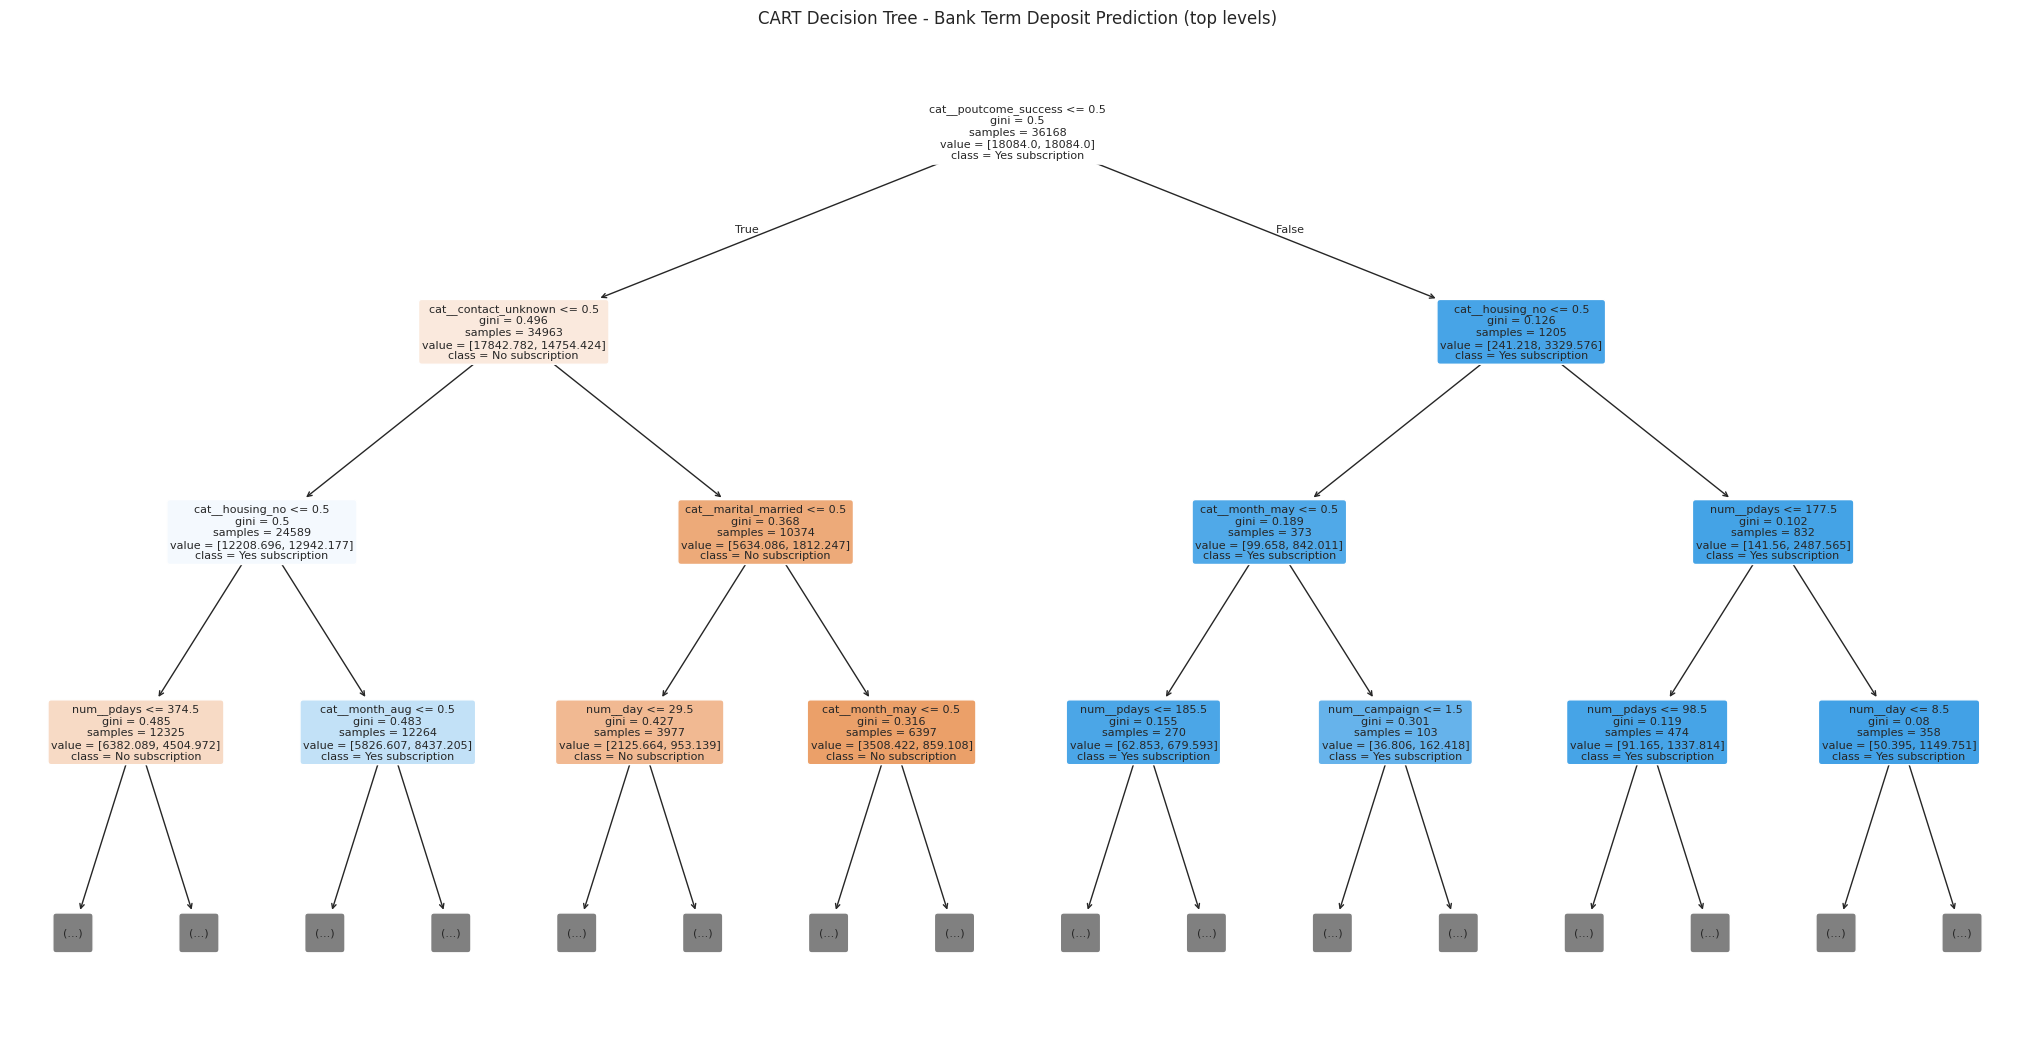

In [20]:
fitted_preprocessor = cart_model.named_steps["preprocessor"]
fitted_tree = cart_model.named_steps["cart"]
feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(26, 13))
plot_tree(
    fitted_tree,
    feature_names=feature_names,
    class_names=["No subscription", "Yes subscription"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("CART Decision Tree - Bank Term Deposit Prediction (top levels)")
plt.show()

## Step 21: Make predictions using CART

In [21]:
y_pred = cart_model.predict(X_test)
y_probability = cart_model.predict_proba(X_test)[:, 1]

prediction_comparison = pd.DataFrame({
    "Actual": y_test.map({0: "no", 1: "yes"}).values,
    "Predicted": pd.Series(y_pred, index=y_test.index).map({0: "no", 1: "yes"}).values
}, index=y_test.index)

display(prediction_comparison.head(10))

,Actual,Predicted
1392,no,no
7518,no,no
12007,no,no
5536,no,no
29816,no,no
18275,no,no
8543,no,no
43965,yes,yes
28083,no,yes
25787,no,yes


## Step 22: Evaluate model accuracy

In [22]:
accuracy = accuracy_score(y_test, y_pred)
print(f"CART Model Accuracy: {accuracy * 100:.2f}%")

CART Model Accuracy: 79.49%


## Step 23: Confusion matrix
Rows represent actual classes and columns represent predicted classes. For the positive class `yes`, false negatives are customers who subscribed but were predicted as `no`; false positives are customers predicted as `yes` who did not subscribe.

Confusion Matrix:
[[6594 1391]
 [ 464  594]]


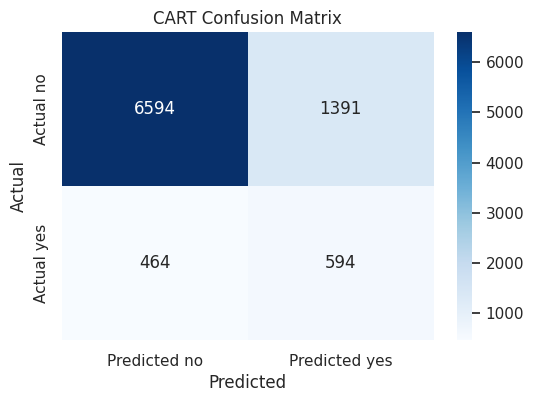

In [23]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted no", "Predicted yes"],
    yticklabels=["Actual no", "Actual yes"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CART Confusion Matrix")
plt.show()

## Step 24: Classification report
Precision answers: of the customers predicted as `yes`, how many actually subscribed? Recall answers: of all customers who subscribed, how many did the model identify? F1-score balances precision and recall.

In [24]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No subscription", "Yes subscription"],
    zero_division=0
))

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print(f"Precision (yes): {precision:.4f}")
print(f"Recall (yes):    {recall:.4f}")
print(f"F1-score (yes):  {f1:.4f}")
print(f"ROC-AUC:         {roc_auc:.4f}")

Classification Report:
                  precision    recall  f1-score   support

 No subscription       0.93      0.83      0.88      7985
Yes subscription       0.30      0.56      0.39      1058

        accuracy                           0.79      9043
       macro avg       0.62      0.69      0.63      9043
    weighted avg       0.86      0.79      0.82      9043

Precision (yes): 0.2992
Recall (yes):    0.5614
F1-score (yes):  0.3904
ROC-AUC:         0.7451


## Step 25: ROC curve

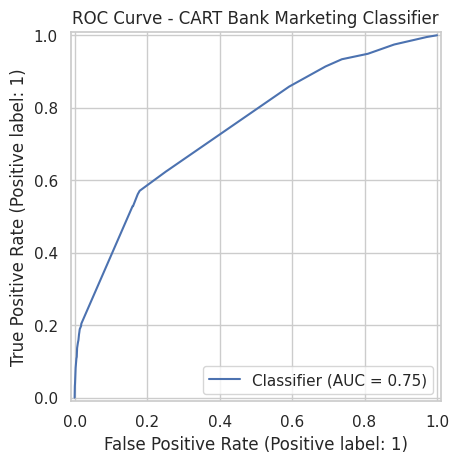

In [25]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - CART Bank Marketing Classifier")
plt.show()

## Step 26: Feature importance
Feature importance measures the relative contribution of each transformed feature to the tree's impurity reduction. It is not a causal explanation.

,Feature,Importance
48,cat__poutcome_success,0.414180
33,cat__contact_unknown,0.236229
27,cat__housing_no,0.110061
35,cat__month_aug,0.067500
39,cat__month_jul,0.063134
3,num__campaign,0.027274
40,cat__month_jun,0.026473
4,num__pdays,0.023481
19,cat__marital_married,0.012862
42,cat__month_may,0.009370


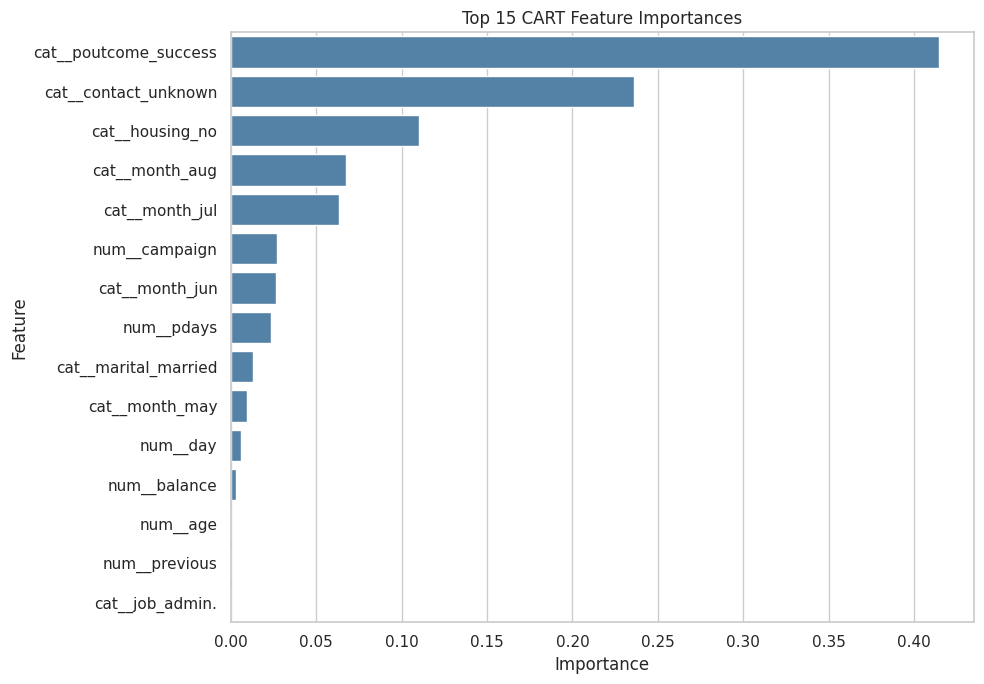

In [26]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_tree.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature", color="steelblue"
)
plt.title("Top 15 CART Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Step 27: Final model performance summary

In [27]:
summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (yes)", "Recall (yes)", "F1-score (yes)", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_probability)
    ]
})
display(summary.style.format({"Score": "{:.4f}"}))

,Metric,Score
0,Accuracy,0.7949
1,Precision (yes),0.2992
2,Recall (yes),0.5614
3,F1-score (yes),0.3904
4,ROC-AUC,0.7451


## Step 28: Conclusion

In this assignment, the CART classification algorithm was implemented using the Bank Marketing dataset to predict whether a customer subscribed to a term deposit.

The dataset was explored, the target variable was encoded, and numerical and categorical features were preprocessed. Parent Gini impurity and example weighted-Gini calculations were used to understand how CART evaluates candidate splits. A Scikit-learn `DecisionTreeClassifier` with the Gini criterion was then trained using an 80:20 stratified train-test split.

The model was evaluated using accuracy, precision, recall, F1-score, a confusion matrix, and ROC-AUC. Because the target classes are imbalanced, precision and recall for the `yes` class are particularly important and should be considered alongside accuracy.

**Modelling note:** `duration` was excluded because it is only known after the contact. Including it in a model intended to predict subscription before a call would introduce information leakage. The results depend on the train-test split and the chosen tree settings; they should be interpreted as an educational baseline, not as a production-ready banking decision system.